# Лабораторна робота № 5. Cassandra: моделювання даних, реплікація і лічильник

Дисципліна «Проєктування високонавантажених систем», викладач Родіонов А. М.

Виконав: Вовкотруб Олександр Віталійович, група ФБ-61мн.
КПІ ім. Ігоря Сікорського, ННФТІ, кафедра інформаційної безпеки.

Ноутбук є аналітичною частиною звіту. Протоколи терміналу частин 1 і 2
беруться з `reports/logs/task5-part{1,2}-*.txt`, і код витягує з них
числа звіту: розподіл даних, доступність рівнів узгодженості при
вимкненому вузлі, мітки часу конфліктних записів. Таблиці частини 3
обчислюються з `reports/data/task5-*.csv` і даних робіт № 1...4. Розділи
7...10 аналізують додаткове дослідження (`reports/data/task5x-*.csv`):
відмови, режими commit log, власний клієнт CQL, застарілі читання і три
способи інкременту. Наприкінці є жива перевірка на справжньому кластері.

## 0. Підготовка середовища

Корінь репозиторію шукаємо від поточної теки вгору до `Package.swift`.
Прапорець `RUN_LIVE` вмикає розділ 7 зі справжнім кластером; вимкнути
його можна змінною оточення `HLS_NB_LIVE=0`.

In [1]:
import os
import re
import shutil
import subprocess
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display


def find_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / "Package.swift").is_file():
            return path
    raise FileNotFoundError("Package.swift не знайдено вище від " + str(start))


ROOT = find_root(Path.cwd().resolve())
LAB = Path.cwd() if (Path.cwd() / "solution.ipynb").is_file() else next(
    p for p in (ROOT / "lab5", ROOT / "Labs" / "05-cassandra") if p.is_dir())
DATA = ROOT / "reports" / "data"
LOGS = ROOT / "reports" / "logs"
ASSETS = LAB / "assets"
ASSETS.mkdir(exist_ok=True)

RUN_LIVE = os.environ.get("HLS_NB_LIVE", "1") != "0"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Liberation Sans", "DejaVu Sans"],
    "font.size": 14,
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 13,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 100,
})
pd.set_option("display.width", 160)

# Ті самі кольори, що й у ноутбуках робіт № 1...4.
INK, GRID = "#1A233B", "#D7DAE3"
STORE_COLOR = {
    "In-memory": "#6B7280",
    "Hazelcast (CP)": "#1B8A5E",
    "Cassandra ONE": "#C27C0E",
    "Cassandra QUORUM": "#8A5A0B",
    "MongoDB (majority)": "#7A4FB5",
    "PostgreSQL": "#0E6BA8",
    "Disk (fsync)": "#B5432F",
}
LEVEL_COLOR = {"ONE": "#C27C0E", "QUORUM": "#8A5A0B"}
EXPECTED = 100_000


def uk(x: float, digits: int = 0) -> str:
    """Число в українському записі: 4 447,0 (нерозривний пробіл, кома)."""
    return f"{x:,.{digits}f}".replace(",", "\u00a0").replace(".", ",")


def save(fig, name: str) -> None:
    """Зберегти рисунок у assets/ (dpi 200) і показати його в ноутбуці."""
    path = ASSETS / name
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path), width=820))
    print("збережено:", path.relative_to(ROOT))


def excerpt(rel: str, start: str, end: str | None = None, *, lines: int | None = None) -> None:
    """Надрукувати точний уривок файла з номерами рядків."""
    text = (ROOT / rel).read_text(encoding="utf-8").splitlines()
    first = next(i for i, line in enumerate(text) if start in line)
    if end is not None:
        last = next(i for i in range(first + 1, len(text)) if end in text[i])
    else:
        last = first + (lines or 1) - 1
    print(f"{rel}, рядки {first + 1}...{last + 1}")
    for i in range(first, last + 1):
        print(f"{i + 1:4d} | {text[i]}")


def transcript(name: str) -> str:
    return (LOGS / f"{name}.txt").read_text(encoding="utf-8")


def answers(text: str, statement: str) -> list[str]:
    """Вивід cqlsh після кожного введення `statement` (до наступної підказки)."""
    out = []
    lines = text.splitlines()
    for i, line in enumerate(lines):
        if re.match(r"^cqlsh(:\w+)?> ", line) and line.split("> ", 1)[1] == statement:
            body = []
            for nxt in lines[i + 1:]:
                if re.match(r"^(cqlsh(:\w+)?> |\[\d\d:|# )", nxt):
                    break
                body.append(nxt)
            out.append("\n".join(body).strip())
    return out


def rows(table: str) -> list[list[str]]:
    """Рядки таблиці, яку надрукував cqlsh, без заголовка."""
    lines = [l for l in table.splitlines() if "|" in l]
    return [[c.strip() for c in l.split("|")] for l in lines[1:]]


print("корінь репозиторію:", ROOT.name)
print("RUN_LIVE =", RUN_LIVE)

корінь репозиторію: HighLoadSystems
RUN_LIVE = True


## 1. Постановка

Кластер з трьох вузлів Cassandra 4.1.12 на одній машині, вузли
`127.0.0.11...13`. Мережу між вузлами можна розірвати проксі
`scripts/netsplit.py`, клієнти бачать вузли напряму.

Частина 1. Keyspace `shop` (`SimpleStrategy`), таблиці `items` (ключ
партиції категорія, clustering за ціною, `map` з індексами,
materialized views за назвою і виробником) і `orders` (ключ партиції
замовник, clustering за датою), запити без `ALLOW FILTERING`.

Частина 2. Keyspace з RF 1, 2, 3; розподіл даних; рівні узгодженості при
вимкненому вузлі; конфлікт записів під час розриву мережі.

Частина 3. Лічильник `counter` у keyspace з RF 3: 10 клієнтів по 10 000
інкрементів з рівнем ONE і QUORUM; Cassandra як сховище веб-лічильника.

## 2. Частина 1: модель даних і запити

Протоколи `task5-part1-{1,2,3}.txt` (рисунки 3.1...3.7 звіту). Схема:

In [2]:
p1 = {n: transcript(f"task5-part1-{n}") for n in (1, 2, 3)}
print(p1[1])

[18:16:45.859] $ scripts/cassandra.sh cqlsh 1
# Keyspace з найпростішою стратегією реплікації: SimpleStrategy кладе копії
# на наступні за кільцем вузли, не зважаючи на стійки й датацентри.
cqlsh> CREATE KEYSPACE IF NOT EXISTS shop
   ...   WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 3};
cqlsh> USE shop;

# category є ключем партиції: усі товари категорії лежать в одній партиції,
# тож пошук за категорією читає одну партицію. Усередині рядки впорядковані
# за ціною (clustering column), id розрізняє товари з однаковою ціною.
cqlsh:shop> CREATE TABLE IF NOT EXISTS items (
   ...   category text,
   ...   price decimal,
   ...   id uuid,
   ...   name text,
   ...   producer text,
   ...   props map<text, text>,
   ...   PRIMARY KEY ((category), price, id)
   ... ) WITH CLUSTERING ORDER BY (price ASC, id ASC);

# Індекси за вмістом map: за парами ключ-значення і за ключами.
cqlsh:shop> CREATE INDEX IF NOT EXISTS items_props_entries ON items (ENTRIES(props));
cqlsh

Запити до `items` і `orders`:

In [3]:
print(p1[2])
print(p1[3])

[18:17:00.517] $ scripts/cassandra.sh cqlsh 1
cqlsh> USE shop;

# Усі телефони за зростанням ціни (порядок clustering column у партиції):
cqlsh:shop> SELECT name, producer, price FROM items WHERE category = 'Телефони';
 name          | producer | price
---------------+----------+-------
 Redmi Note 13 |   Xiaomi |  7499
    Galaxy A55 |  Samsung | 12999
    Galaxy S24 |  Samsung | 18999
       Pixel 9 |   Google | 29999
 iPhone 16 Pro |    Apple | 41999

(5 rows)
# Те саме, від найдорожчого:
cqlsh:shop> SELECT name, producer, price FROM items WHERE category = 'Телефони' ORDER BY price DESC;
 name          | producer | price
---------------+----------+-------
 iPhone 16 Pro |    Apple | 41999
       Pixel 9 |   Google | 29999
    Galaxy S24 |  Samsung | 18999
    Galaxy A55 |  Samsung | 12999
 Redmi Note 13 |   Xiaomi |  7499

(5 rows)

# За назвою в межах категорії, через view items_by_name:
cqlsh:shop> SELECT category, name, producer, price FROM items_by_name WHERE category = 'Ноутбук

Перевірка результатів запитів: порядок за ціною, вибірки через view і
індекси, відмова без ключа партиції, суми замовлень і `WRITETIME`.

In [4]:
t = p1[2]
phones = rows(answers(t, "SELECT name, producer, price FROM items WHERE category = 'Телефони';")[0])
prices = [int(r[2]) for r in phones]
assert prices == sorted(prices) and len(prices) == 5
desc = rows(answers(t, "SELECT name, producer, price FROM items WHERE category = 'Телефони' ORDER BY price DESC;")[0])
assert [int(r[2]) for r in desc] == sorted(prices, reverse=True)
by_name = rows(answers(t, "SELECT category, name, producer, price FROM items_by_name "
                          "WHERE category = 'Ноутбуки' AND name = 'ThinkPad T14';")[0])
in_range = rows(answers(t, "SELECT name, producer, price FROM items WHERE category = 'Ноутбуки' "
                           "AND price >= 35000 AND price <= 50000;")[0])
by_producer = rows(answers(t, "SELECT name, producer, price FROM items_by_producer WHERE category = 'Телефони' "
                              "AND producer = 'Samsung' AND price < 15000;")[0])
black = rows(answers(t, "SELECT name, price, props FROM items WHERE category = 'Телефони' AND props['колір'] = 'чорний';")[0])
esim = rows(answers(t, "SELECT name, price, props FROM items WHERE category = 'Телефони' AND props CONTAINS KEY 'eSIM';")[0])
refused = answers(t, "SELECT name, price FROM items WHERE price > 40000;")[0]
display(pd.DataFrame({
    "запит": ["телефони за ціною", "за назвою (view)", "ціна 35000...50000", "Samsung < 15000 (view)",
              "колір чорний (індекс ENTRIES)", "є ключ eSIM (індекс KEYS)"],
    "результат": [", ".join(r[0] for r in phones), by_name[0][1], ", ".join(r[0] for r in in_range),
                  ", ".join(r[0] for r in by_producer), ", ".join(r[0] for r in black), ", ".join(r[0] for r in esim)],
}))
print("без ключа партиції:", refused[:90], "...")
assert [r[0] for r in in_range] == ["Zenbook 14 OLED", "ThinkPad T14"]
assert [r[0] for r in by_producer] == ["Galaxy A55"]
assert len(black) == 2 and len(esim) == 2 and "ALLOW FILTERING" in refused

,запит,результат
0,телефони за ціною,"Redmi Note 13, Galaxy A55, Galaxy S24, Pixel 9..."
1,за назвою (view),ThinkPad T14
2,ціна 35000...50000,"Zenbook 14 OLED, ThinkPad T14"
3,Samsung < 15000 (view),Galaxy A55
4,колір чорний (індекс ENTRIES),"Redmi Note 13, Galaxy S24"
5,є ключ eSIM (індекс KEYS),"Pixel 9, iPhone 16 Pro"


без ключа партиції: InvalidRequest: Error from server: code=2200 [Invalid query] message="Cannot execute this  ...


In [5]:
t = p1[3]
totals = rows(answers(t, "SELECT customer, COUNT(*) AS orders, SUM(total) AS spent FROM orders GROUP BY customer;")[0])
totals = pd.DataFrame(totals, columns=["замовник", "замовлень", "сума"]).astype({"замовлень": int, "сума": int})
display(totals)
wt = rows(answers(t, "SELECT customer, order_date, total, WRITETIME(total) AS total_written FROM orders;")[0])
wt = pd.DataFrame(wt, columns=["замовник", "дата", "ціна", "writetime"])
wt["записано (UTC)"] = pd.to_datetime(wt["writetime"].astype("int64"), unit="us")
display(wt)
corrected = wt.loc[wt["ціна"] == "69998", "записано (UTC)"].iloc[0]
others = wt.loc[wt["ціна"] != "69998", "записано (UTC)"]
gap = (corrected - others.max()).total_seconds()
print(f"виправлену ціну записано на {gap:.1f} с пізніше за решту")
assert dict(zip(totals["замовник"], totals["сума"])) == {
    "Андрій Мельник": 87997, "Олена Коваль": 97496, "Ірина Бондар": 142997}
assert round(gap) == 7

,замовник,замовлень,сума
0,Андрій Мельник,2,87997
1,Олена Коваль,3,97496
2,Ірина Бондар,2,142997


,замовник,дата,ціна,writetime,записано (UTC)
0,Андрій Мельник,2026-11-02 20:30:00.000000+0000,45998,1794853020415442,2026-11-16 18:17:00.415442
1,Андрій Мельник,2026-08-30 12:00:00.000000+0000,41999,1794853020412480,2026-11-16 18:17:00.412480
2,Олена Коваль,2026-11-12 09:05:00.000000+0000,7499,1794853020409319,2026-11-16 18:17:00.409319
3,Олена Коваль,2026-10-21 18:40:00.000000+0000,69998,1794853027250773,2026-11-16 18:17:07.250773
4,Олена Коваль,2026-09-03 10:15:00.000000+0000,18999,1794853020401827,2026-11-16 18:17:00.401827
5,Ірина Бондар,2026-10-05 14:25:00.000000+0000,77998,1794853020423437,2026-11-16 18:17:00.423437
6,Ірина Бондар,2026-10-05 14:20:00.000000+0000,64999,1794853020419644,2026-11-16 18:17:00.419644


виправлену ціну записано на 6.8 с пізніше за решту


Сума Олени Коваль у протоколі порахована до виправлення ціни (запит
`GROUP BY` іде раніше за `UPDATE`): 18 999 + 70 998 + 7 499 = 97 496.

## 3. Частина 2: розподіл даних між вузлами

З протоколу `task5-part2-2.txt` (рисунки 3.10, 3.11): `Owns (effective)`
кожного вузла, кількість партицій таблиці `kv` на кожному вузлі і репліки
рядка `id = 7`.

In [6]:
t = transcript("task5-part2-2")
NODE = {"127.0.0.11": "node1", "127.0.0.12": "node2", "127.0.0.13": "node3"}
dist = []
for ks in ("ks_rf1", "ks_rf2", "ks_rf3"):
    status = t.split(f"nodetool 1 status {ks}\n", 1)[1].split("\n\n", 1)[0]
    owns = {NODE[m[1]]: float(m[2].replace(",", ".")) for m in re.finditer(r"^UN\s+(\S+)\s.*?(\d+,\d)%", status, re.M)}
    parts = [int(x) for x in re.findall(rf"tablestats {ks}\.kv.*\nNumber of partitions \(estimate\): (\d+)", t)]
    ends = t.split(f"getendpoints {ks} kv 7\n", 1)[1].split("\n\n", 1)[0].split()
    dist.append({"keyspace": ks, **{f"owns {n}, %": owns[n] for n in ("node1", "node2", "node3")},
                 "сума owns, %": round(sum(owns.values()), 1),
                 "партицій node1/2/3": " / ".join(map(str, parts)), "партицій разом": sum(parts),
                 "репліки id = 7": ", ".join(NODE[e] for e in ends)})
dist = pd.DataFrame(dist).set_index("keyspace")
display(dist)
assert list(dist["сума owns, %"]) == [100.0, 200.0, 300.0]
assert list(dist["партицій разом"]) == [1001, 2002, 3003]

,"owns node1, %","owns node2, %","owns node3, %","сума owns, %",партицій node1/2/3,партицій разом,репліки id = 7
keyspace,,,,,,,
ks_rf1,32.7,31.6,35.7,100.0,320 / 316 / 365,1001,node3
ks_rf2,64.7,59.3,76.0,200.0,653 / 587 / 762,2002,"node3, node1"
ks_rf3,100.0,100.0,100.0,300.0,1001 / 1001 / 1001,3003,"node3, node1, node2"


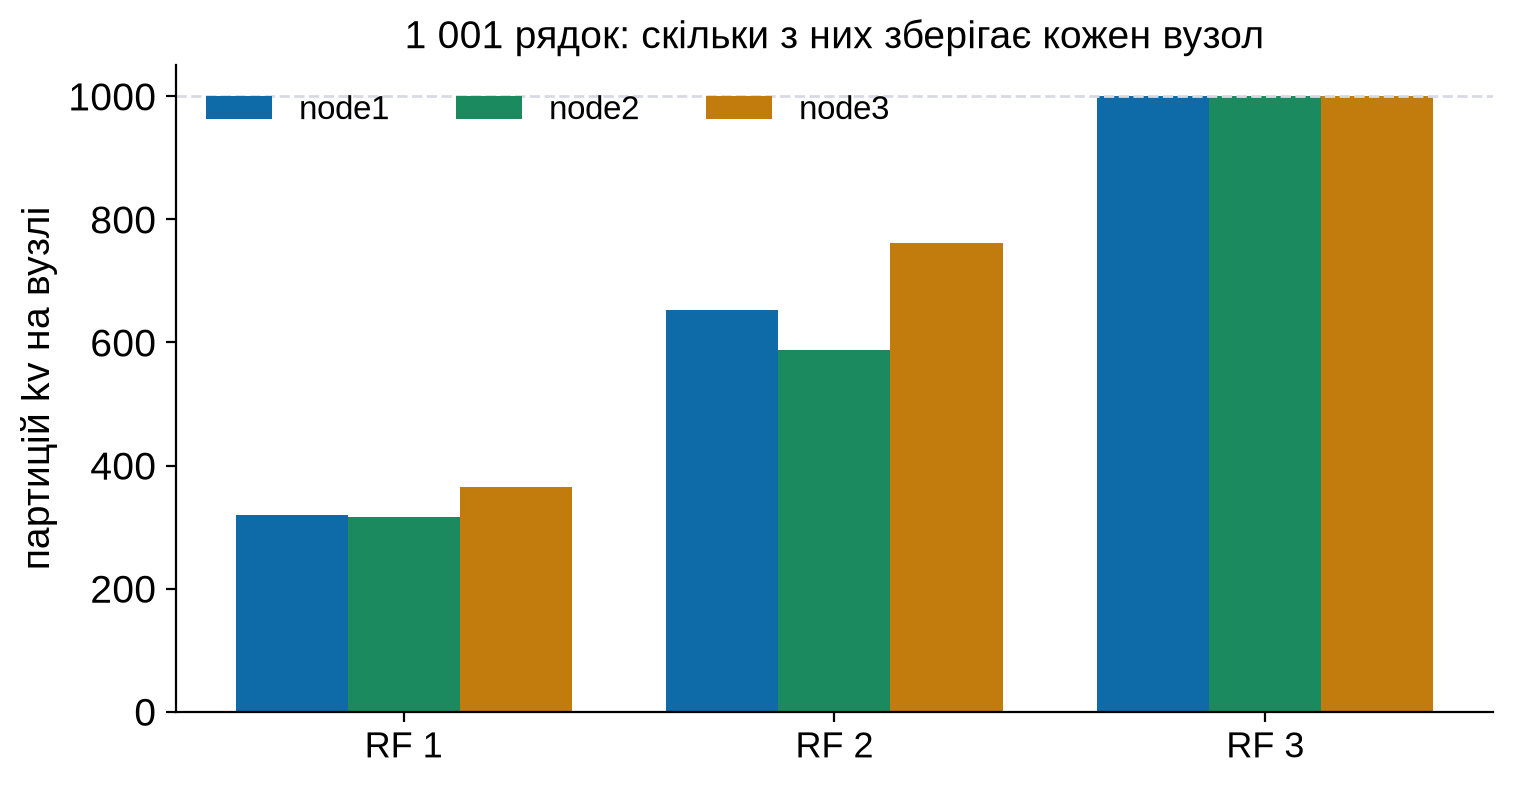

збережено: Labs/05-cassandra/assets/distribution.png


In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = range(3)
width = 0.26
for i, node in enumerate(("node1", "node2", "node3")):
    vals = [int(s.split(" / ")[i]) for s in dist["партицій node1/2/3"]]
    ax.bar([v + (i - 1) * width for v in x], vals, width, label=node,
           color=("#0E6BA8", "#1B8A5E", "#C27C0E")[i])
ax.set_xticks(list(x), ["RF 1", "RF 2", "RF 3"])
ax.set_ylabel("партицій kv на вузлі")
ax.axhline(1001, color=GRID, lw=1, ls="--")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.set_title("1 001 рядок: скільки з них зберігає кожен вузол")
save(fig, "distribution.png")

## 4. Частина 2: вимкнений вузол і конфлікт записів

`task5-part2-3.txt` (рисунки 3.12...3.14): для кожного рядка, кожного
рівня й операції код визначає, чи вона вдалась.

In [8]:
t = transcript("task5-part2-3")
cases = []
for block in re.split(r"\n(?=# ks_rf)", t)[1:]:
    head = block.splitlines()[0]
    ks, key = re.search(r"# (ks_rf\d), id = (\d+)", head).groups()
    replicas = re.search(r"репліки на вузлах ([\d, ]+?),? (?:серед|node3)", head)[1]
    level = None
    row = {"keyspace": ks, "id": int(key), "репліки": replicas}
    lines = block.splitlines()
    for i, line in enumerate(lines):
        if m := re.match(r"cqlsh> CONSISTENCY (\w+)", line):
            level = m[1]
        elif m := re.match(r"cqlsh> (INSERT|SELECT)", line):
            op = "запис" if m[1] == "INSERT" else "читання"
            ok = not (i + 1 < len(lines) and lines[i + 1].startswith("NoHostAvailable"))
            row[f"{level} {op}"] = "так" if ok else "ні"
    cases.append(row)
cl = pd.DataFrame(cases).fillna("")
display(cl)
expect = {("ks_rf1", "3"): {"ONE": "ні"}, ("ks_rf1", "1"): {"ONE": "так"},
          ("ks_rf2", "1, 3"): {"ONE": "так", "TWO": "ні"}, ("ks_rf2", "1, 2"): {"ONE": "так", "TWO": "так"},
          ("ks_rf3", "1, 2, 3"): {"ONE": "так", "TWO": "так", "THREE": "ні"}}
for _, r in cl.iterrows():
    for level, want in expect[(r["keyspace"], r["репліки"])].items():
        assert r[f"{level} запис"] == want and r[f"{level} читання"] == want, (r["keyspace"], level)
print("правило підтверджено: рівень k доступний, коли живі щонайменше k реплік рядка")

,keyspace,id,репліки,ONE запис,ONE читання,TWO запис,TWO читання,THREE запис,THREE читання
0,ks_rf1,4,3,ні,ні,,,,
1,ks_rf1,1,1,так,так,,,,
2,ks_rf2,1,"1, 3",так,так,ні,ні,,
3,ks_rf2,6,"1, 2",так,так,так,так,,
4,ks_rf3,1,"1, 2, 3",так,так,так,так,ні,ні


правило підтверджено: рівень k доступний, коли живі щонайменше k реплік рядка


`task5-part2-4.txt` і `task5-part2-5.txt` (рисунки 3.15...3.19): під час
розриву кожен вузол записав своє значення; після відновлення всі вузли
повертають одне значення. Мітки `WRITETIME` переводимо в час UTC.

In [9]:
t4, t5 = transcript("task5-part2-4"), transcript("task5-part2-5")
written = []
for m in re.finditer(r"^ (10[01]) \| ([^|]+?) \| (\d{16})$", t4, re.M):
    written.append({"id": int(m[1]), "значення": m[2].strip(), "writetime": int(m[3])})
written = pd.DataFrame(written).drop_duplicates()
written["мітка (UTC)"] = pd.to_datetime(written["writetime"], unit="us")
display(written)
final = pd.DataFrame([{"id": int(m[1]), "значення": m[2].strip(), "writetime": int(m[3])}
                      for m in re.finditer(r"^ (10[01]) \| ([^|]+?) \| (\d{16})$", t5, re.M)])
print("читань після відновлення:", len(final) // 2, "(через node1, node2, node3 з ONE і через node1 з ALL)")
final = final.drop_duplicates()
display(final)
winners = written.loc[written.groupby("id")["writetime"].idxmax(), ["id", "значення"]]
assert len(final) == 2 and final.set_index("id")["значення"].to_dict() == winners.set_index("id")["значення"].to_dict()
print("переможець кожного конфлікту = запис з найбільшою міткою часу:",
      final.set_index("id")["значення"].to_dict())
quorum_refused = "Cannot achieve consistency level QUORUM" in t4
handoffs = len(re.findall(r"^\S+ \S+ Finished hinted handoff", t5, re.M))
assert quorum_refused and handoffs == 6
gossip = transcript("task5-part2-gossip")
day = re.search(r"^(\d{4}-\d\d-\d\d) ", gossip, re.M)[1]
split_at = pd.Timestamp(f"{day} " + re.search(r"split о ([\d:]+\.\d+)", gossip)[1])
heal_at = pd.Timestamp(f"{day} " + re.search(r"heal о ([\d:]+\.\d+)", gossip)[1])
events = pd.DataFrame([(pd.Timestamp(m[1].replace(",", ".")), m[2], m[3]) for m in re.finditer(
    r"^(\S+ \S+)  (node\d): node\d is now (DOWN|UP)", gossip, re.M)], columns=["час", "вузол", "подія"])
down = events[events["подія"] == "DOWN"]["час"]
up = events[events["подія"] == "UP"]["час"]
print(gossip)
print(f"від split до DOWN: {(down.min() - split_at).total_seconds():.1f}...{(down.max() - split_at).total_seconds():.1f} с "
      f"({len(down)} подій: кожен вузол про кожного з двох інших)")
print(f"від heal до UP: {(up.min() - heal_at).total_seconds():.2f}...{(up.max() - heal_at).total_seconds():.2f} с")
assert len(down) == 6 and len(up) == 6
handoff_at = [pd.Timestamp(x.replace(",", ".")) for x in re.findall(r"^(\S+ \S+) Finished hinted handoff", t5, re.M)]
print("hinted handoff після heal: " + ", ".join(f"{(h - heal_at).total_seconds():.1f}" for h in handoff_at) + " с")

,id,значення,writetime,мітка (UTC)
0,100,з node1,1794863002494468,2026-11-16 21:03:22.494468
1,100,з node2,1794863005324226,2026-11-16 21:03:25.324226
2,100,з node3,1794863008317830,2026-11-16 21:03:28.317830
3,101,"з node1, раніше",1794863013513193,2026-11-16 21:03:33.513193
4,101,"з node2, пізніше",1794863013513192,2026-11-16 21:03:33.513192


читань після відновлення: 4 (через node1, node2, node3 з ONE і через node1 з ALL)


,id,значення,writetime
0,100,з node3,1794863008317830
1,101,"з node1, раніше",1794863013513193


переможець кожного конфлікту = запис з найбільшою міткою часу: {100: 'з node3', 101: 'з node1, раніше'}
# Події gossip з system.log вузлів (UTC): split о 21:01:48.803, heal о 21:03:58.554.
2026-11-16 21:02:06,663  node3: node1 is now DOWN
2026-11-16 21:02:06,664  node3: node2 is now DOWN
2026-11-16 21:02:07,674  node2: node1 is now DOWN
2026-11-16 21:02:07,674  node2: node3 is now DOWN
2026-11-16 21:02:07,920  node1: node2 is now DOWN
2026-11-16 21:02:07,920  node1: node3 is now DOWN
2026-11-16 21:03:59,015  node2: node3 is now UP
2026-11-16 21:03:59,015  node3: node2 is now UP
2026-11-16 21:03:59,247  node2: node1 is now UP
2026-11-16 21:03:59,248  node1: node2 is now UP
2026-11-16 21:03:59,256  node3: node1 is now UP
2026-11-16 21:03:59,259  node1: node3 is now UP

від split до DOWN: 17.9...19.1 с (6 подій: кожен вузол про кожного з двох інших)
від heal до UP: 0.46...0.70 с
hinted handoff після heal: 11.2, 11.2, 14.0, 14.0, 17.2, 17.2 с


## 5. Частина 3: лічильник `counter`, ONE і QUORUM

`cassandra-bench` (`Sources/cassandra-bench/`): 10 окремих клієнтів (у
кожного свій `CassandraClient` зі з'єднаннями до всіх вузлів), по 10 000
`UPDATE counter_rf3.likes SET likes = likes + 1 WHERE id = 'post-1'`.
Інкремент не повторюється після помилки, бо він не ідемпотентний.

In [10]:
excerpt("Sources/CounterCore/CassandraCounterStore.swift", "public func increment() async throws", lines=3)

Sources/CounterCore/CassandraCounterStore.swift, рядки 104...106
 104 |     public func increment() async throws {
 105 |         _ = try await client.execute(prepared: incrementStatement, parameters: [.string(location.row)], options: options)
 106 |     }


In [11]:
bench = pd.read_csv(DATA / "task5-bench.csv")
display(bench)
assert (bench["expected"] == EXPECTED).all()
g = bench.groupby("consistency", sort=False)
part3 = pd.DataFrame({
    "прогонів": g.size(),
    "медіана, с": g["seconds"].median(),
    "мін., с": g["seconds"].min(),
    "макс., с": g["seconds"].max(),
    "інкр./с (медіана)": g["ops_per_sec"].median(),
    "p50, мс (медіана)": g["p50_ms"].median(),
    "p99, мс (медіана)": g["p99_ms"].median(),
    "фінальні значення": g["final_value"].agg(list),
    "помилок": g["errors"].sum(),
}).loc[["ONE", "QUORUM"]]
display(part3.round(3))

PUBLISHED_41 = {  # рівень: (медіана, мін., макс., інкр./с, p50, p99), як у таблиці 4.1 звіту
    "ONE": (22.42, 21.63, 34.69, 4459.3, 1.98, 7.27),
    "QUORUM": (28.43, 27.71, 31.21, 3517.8, 2.48, 8.87),
}
for level, values in PUBLISHED_41.items():
    r = part3.loc[level]
    got = (round(r["медіана, с"], 2), round(r["мін., с"], 2), round(r["макс., с"], 2),
           round(r["інкр./с (медіана)"], 1), round(r["p50, мс (медіана)"], 2), round(r["p99, мс (медіана)"], 2))
    assert got == values and r["фінальні значення"] == [EXPECTED] * 3 and r["помилок"] == 0, (level, got)
print(f"QUORUM / ONE за медіанним часом: {part3.loc['QUORUM', 'медіана, с'] / part3.loc['ONE', 'медіана, с']:.2f}")

,repeat,consistency,workers,increments_per_worker,seconds,ops_per_sec,final_value,expected,acknowledged,errors,p50_ms,p99_ms,max_ms
0,1,ONE,10,10000,34.6879,2882.9,100000,100000,100000,0,2.340,19.457,74.947
1,1,QUORUM,10,10000,28.4265,3517.8,100000,100000,100000,0,2.475,8.871,37.588
2,2,ONE,10,10000,21.6260,4624.1,100000,100000,100000,0,1.921,6.863,22.351
3,2,QUORUM,10,10000,27.7149,3608.2,100000,100000,100000,0,2.418,8.211,37.839
4,3,ONE,10,10000,22.4248,4459.3,100000,100000,100000,0,1.978,7.271,47.061
5,3,QUORUM,10,10000,31.2129,3203.8,100000,100000,100000,0,2.573,11.304,87.078


,прогонів,"медіана, с","мін., с","макс., с",інкр./с (медіана),"p50, мс (медіана)","p99, мс (медіана)",фінальні значення,помилок
consistency,,,,,,,,,
ONE,3,22.425,21.626,34.688,4459.3,1.978,7.271,"[100000, 100000, 100000]",0
QUORUM,3,28.426,27.715,31.213,3517.8,2.475,8.871,"[100000, 100000, 100000]",0


QUORUM / ONE за медіанним часом: 1.27


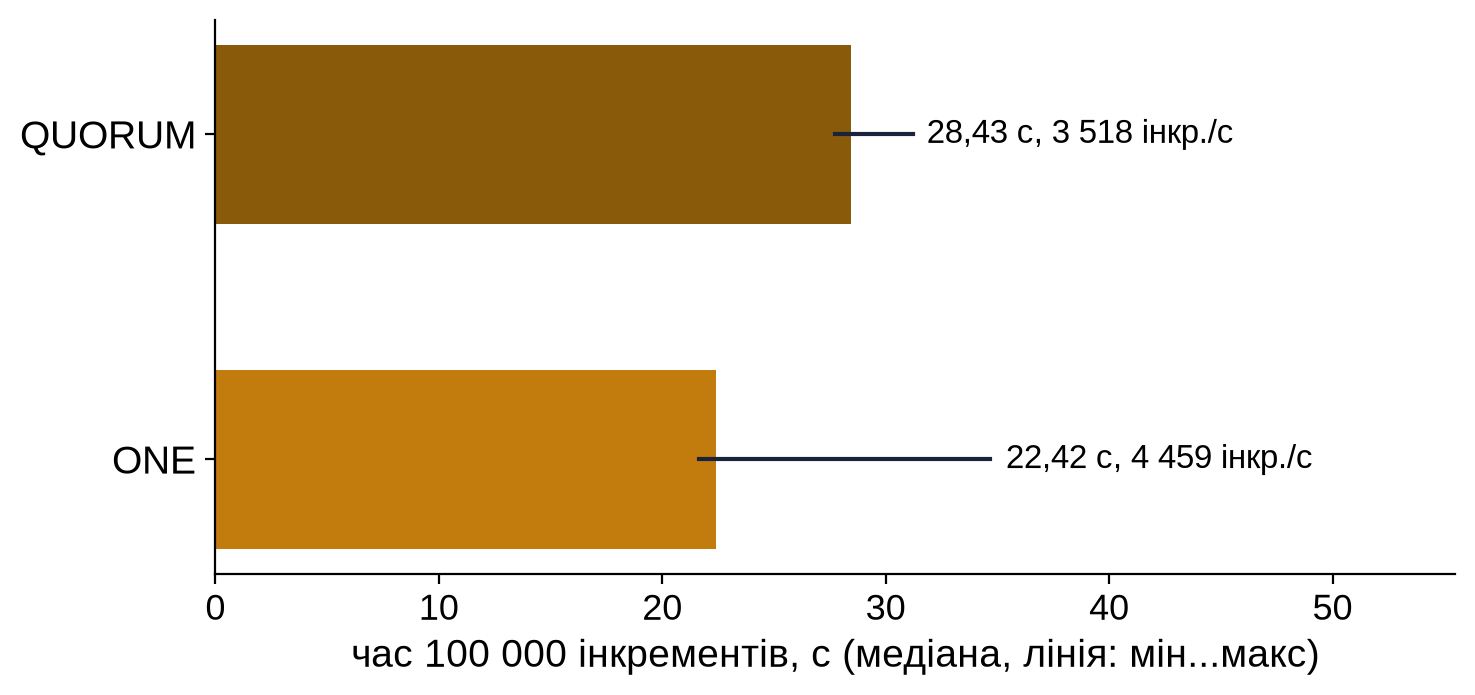

збережено: Labs/05-cassandra/assets/counter-levels.png


In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, level in enumerate(part3.index):
    row = part3.loc[level]
    ax.barh(i, row["медіана, с"], color=LEVEL_COLOR[level], height=0.55)
    ax.plot([row["мін., с"], row["макс., с"]], [i, i], color=INK, lw=1.5)
    ax.text(row["макс., с"] * 1.02, i, f"{uk(row['медіана, с'], 2)} с, {uk(row['інкр./с (медіана)'])} інкр./с",
            va="center", fontsize=12)
ax.set_yticks(range(len(part3)), part3.index)
ax.set_xlabel("час 100 000 інкрементів, с (медіана, лінія: мін...макс)")
ax.set_xlim(0, part3["макс., с"].max() * 1.6)
save(fig, "counter-levels.png")

## 6. Частина 3: веб-лічильник і порівняння сховищ

`counter-server --store cassandra --cassandra-consistency one|quorum` і
`loadgen`, 10 клієнтів по 10 000 запитів, тричі
(`reports/data/task5-web.csv`). Інші сховища: `task1.csv` (рядки з 10
клієнтами), `task2-web.csv`, `task3-web.csv`, `task4-web.csv`.

In [13]:
web = pd.read_csv(DATA / "task5-web.csv")
display(web)
LABEL = {"memory": "In-memory", "disk": "Disk (fsync)", "postgres": "PostgreSQL", "hazelcast": "Hazelcast (CP)",
         "mongo": "MongoDB (majority)", "cassandra-one": "Cassandra ONE", "cassandra-quorum": "Cassandra QUORUM"}
frames = [pd.read_csv(DATA / f) for f in ("task1.csv", "task2-web.csv", "task3-web.csv", "task4-web.csv")] + [web]
allweb = pd.concat(frames)
allweb = allweb[allweb["clients"] == 10]
g = allweb.groupby("store")
compare = pd.DataFrame({
    "прогонів": g.size(),
    "час, с (медіана)": g["seconds"].median(),
    "запитів/с (медіана)": g["rps"].median(),
    "мін. запитів/с": g["rps"].min(),
    "макс. запитів/с": g["rps"].max(),
    "усі значення точні": g["correct"].all(),
}).rename(index=LABEL).sort_values("запитів/с (медіана)", ascending=False)
display(compare.round(1))
assert compare["усі значення точні"].all()
PUBLISHED_42 = {"Cassandra ONE": (27.36, 3654.6), "Cassandra QUORUM": (31.60, 3164.4),
                "MongoDB (majority)": (133.59, 748.6), "PostgreSQL": (302.44, 330.6)}
for store, (sec, rps) in PUBLISHED_42.items():
    assert (round(compare.loc[store, "час, с (медіана)"], 2), compare.loc[store, "запитів/с (медіана)"]) == (sec, rps), store
rps = compare["запитів/с (медіана)"]
print(f"Cassandra QUORUM / MongoDB: {rps['Cassandra QUORUM'] / rps['MongoDB (majority)']:.1f}, "
      f"/ PostgreSQL: {rps['Cassandra QUORUM'] / rps['PostgreSQL']:.1f}, "
      f"Hazelcast / Cassandra QUORUM: {rps['Hazelcast (CP)'] / rps['Cassandra QUORUM']:.1f}")

,repeat,store,clients,requests_per_client,total_requests,seconds,rps,final_value,expected,correct
0,1,cassandra-one,10,10000,100000,27.3625,3654.6,100000,100000,True
1,2,cassandra-one,10,10000,100000,24.4164,4095.6,100000,100000,True
2,3,cassandra-one,10,10000,100000,29.2545,3418.3,100000,100000,True
3,1,cassandra-quorum,10,10000,100000,30.7823,3248.6,100000,100000,True
4,2,cassandra-quorum,10,10000,100000,31.6011,3164.4,100000,100000,True
5,3,cassandra-quorum,10,10000,100000,35.8218,2791.6,100000,100000,True


,прогонів,"час, с (медіана)",запитів/с (медіана),мін. запитів/с,макс. запитів/с,усі значення точні
store,,,,,,
In-memory,3,3.2,31256.0,30215.1,34299.7,True
Hazelcast (CP),3,8.9,11259.7,11007.6,11378.6,True
Cassandra ONE,3,27.4,3654.6,3418.3,4095.6,True
Cassandra QUORUM,3,31.6,3164.4,2791.6,3248.6,True
MongoDB (majority),3,133.6,748.6,641.0,821.1,True
PostgreSQL,3,302.4,330.6,326.6,500.6,True
Disk (fsync),3,818.1,122.2,121.3,122.8,True


Cassandra QUORUM / MongoDB: 4.2, / PostgreSQL: 9.6, Hazelcast / Cassandra QUORUM: 3.6


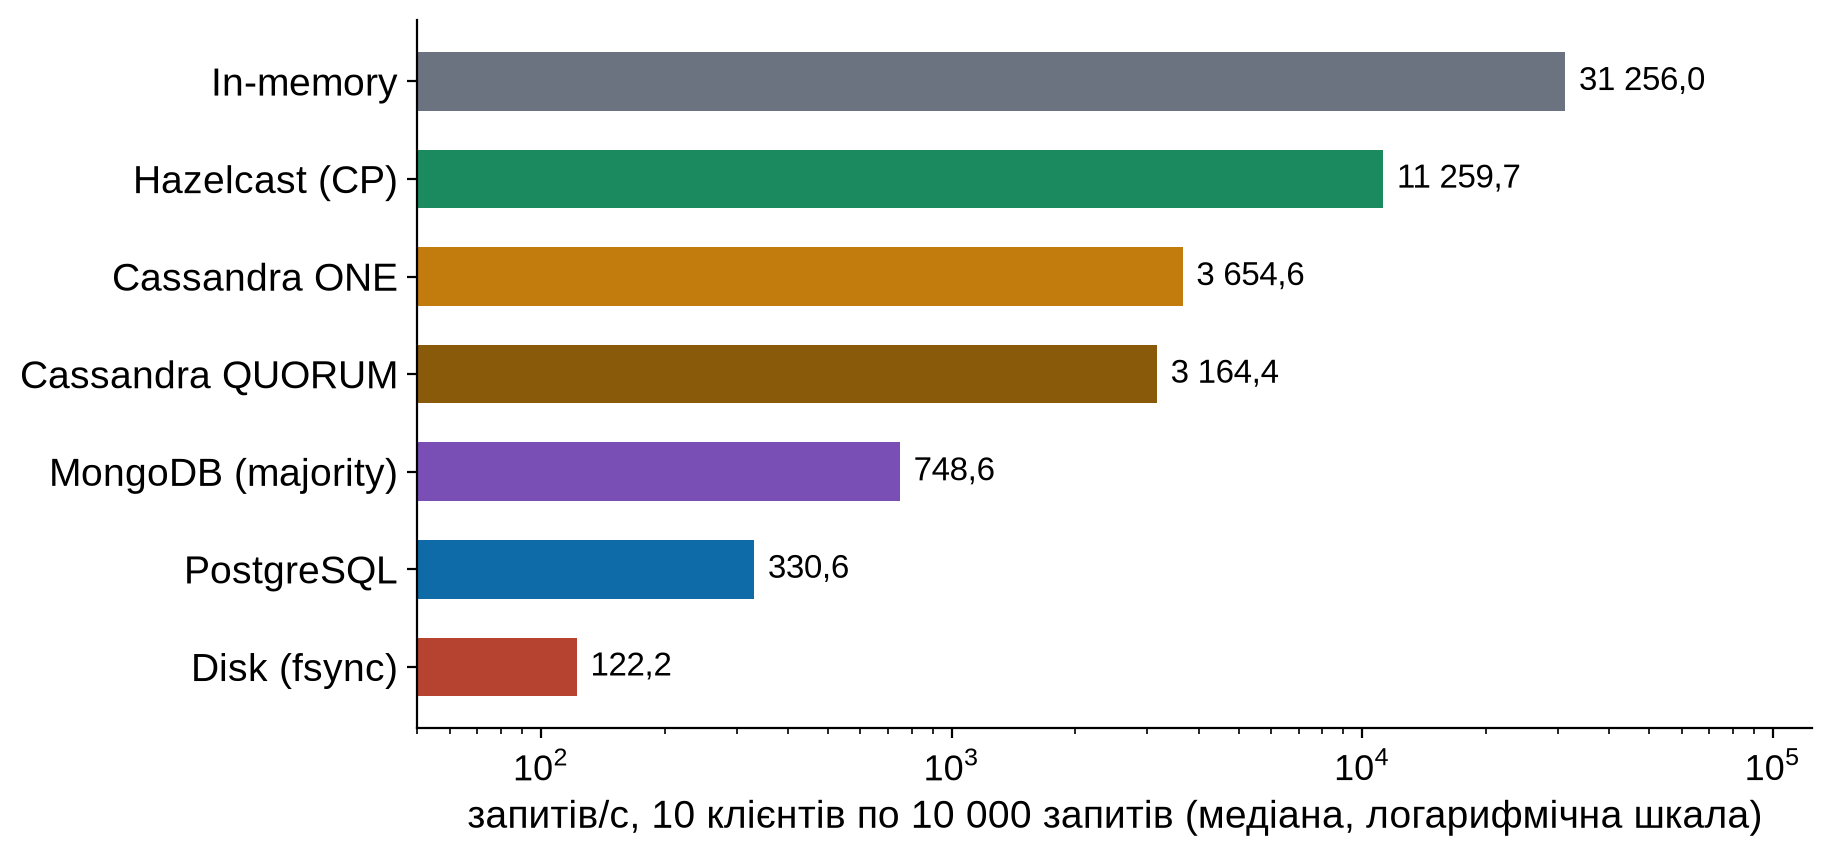

збережено: Labs/05-cassandra/assets/stores.png


In [14]:
fig, ax = plt.subplots(figsize=(9, 4.6))
order = list(compare.index)[::-1]
vals = compare.loc[order, "запитів/с (медіана)"]
ax.barh(range(len(order)), vals, color=[STORE_COLOR[s] for s in order], height=0.6)
for i, v in enumerate(vals):
    ax.text(v * 1.08, i, uk(v, 1), va="center", fontsize=12)
ax.set_xscale("log")
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("запитів/с, 10 клієнтів по 10 000 запитів (медіана, логарифмічна шкала)")
ax.set_xlim(50, vals.max() * 4)
save(fig, "stores.png")

## 7. Додаткове дослідження: лічильник під час відмов

`scripts/task5x-failures.sh`: той самий прогін 10 × 10 000 інкрементів з
ONE або QUORUM і читачем на тому ж рівні, але на 7-й секунді
`cassandra-bench` вбиває node2 (`kill`), розриває мережу на 10 с (`split`)
або вбиває всі три вузли й запускає їх знову (`killall`). Варіанти `-retry`
повторюють невдалий інкремент. `applied_unacknowledged` = фінальне значення
мінус підтверджені інкременти: додатне означає застосовані без
підтвердження, від'ємне означає втрачені підтверджені.

In [15]:
fail = pd.read_csv(DATA / "task5x-failures.csv")
RUN_ORDER = ["kill-one", "kill-one-retry", "kill-quorum", "kill-quorum-retry",
             "split-one", "split-one-retry", "split-quorum", "split-quorum-retry",
             "killall-one", "killall-one-retry", "killall-quorum"]
assert set(fail["label"]) == set(RUN_ORDER) and (fail.groupby("label").size() == 3).all()
g = fail.groupby("label")
failures = pd.DataFrame({
    "фінальні значення": g["final_value"].agg(list),
    "підтверджено": g["acknowledged"].agg(list),
    "помилок": g["errors"].agg(list),
    "повторів": g["retries"].agg(list),
    "застосовано без підтвердження": g["applied_unacknowledged"].agg(list),
    "читань назад": g["reader_backwards"].agg(list),
    "застарілих читань": g["reader_stale"].agg(list),
}).loc[RUN_ORDER]
display(failures)

,фінальні значення,підтверджено,помилок,повторів,застосовано без підтвердження,читань назад,застарілих читань
label,,,,,,,
kill-one,"[99958, 99958, 99956]","[99952, 99954, 99954]","[48, 46, 46]","[0, 0, 0]","[6, 4, 2]","[1169, 4034, 0]","[49, 109, 69]"
kill-one-retry,"[100002, 100002, 100003]","[100000, 100000, 100000]","[0, 0, 0]","[46, 48, 45]","[2, 2, 3]","[3924, 9, 2166]","[116, 125, 66]"
kill-quorum,"[99957, 99960, 99955]","[99954, 99955, 99954]","[46, 45, 46]","[0, 0, 0]","[3, 5, 1]","[0, 0, 0]","[0, 0, 0]"
kill-quorum-retry,"[100001, 100002, 100002]","[100000, 100000, 100000]","[0, 0, 0]","[45, 46, 47]","[1, 2, 2]","[0, 0, 0]","[0, 0, 0]"
split-one,"[99985, 99987, 99984]","[99980, 99980, 99980]","[20, 20, 20]","[0, 0, 0]","[5, 7, 4]","[21, 2670, 246]","[408, 2917, 424]"
split-one-retry,"[100004, 100004, 100003]","[100000, 100000, 100000]","[0, 0, 0]","[20, 20, 20]","[4, 4, 3]","[1511, 243, 1519]","[2964, 396, 2540]"
split-quorum,"[99992, 99995, 99995]","[99975, 99977, 99975]","[25, 23, 25]","[0, 0, 0]","[17, 18, 20]","[0, 0, 0]","[0, 0, 0]"
split-quorum-retry,"[100015, 100012, 100015]","[100000, 100000, 100000]","[0, 0, 0]","[25, 22, 23]","[15, 12, 15]","[0, 0, 0]","[0, 0, 0]"
killall-one,"[44465, 23660, 75285]","[44465, 23661, 75312]","[55535, 76339, 24688]","[0, 0, 0]","[0, -1, -27]","[23615, 23965, 27208]","[23681, 29093, 27248]"


In [16]:
k = fail[fail["label"].str.startswith(("kill-", "split-"))]
lost_partial = (k["applied_unacknowledged"] < 0).sum()
print("kill і split: прогонів з втраченими підтвердженими інкрементами:", lost_partial)
print("  застосовано без підтвердження:", k["applied_unacknowledged"].min(), "...", k["applied_unacknowledged"].max())
retry = k[k["retry"]]
print("  з повторами фінальне значення:", retry["final_value"].min(), "...", retry["final_value"].max())
quorum = fail[(fail["consistency"] == "QUORUM") & ~fail["label"].str.startswith("killall")]
print("читач QUORUM (kill і split): читань назад", quorum["reader_backwards"].sum(), ", застарілих", quorum["reader_stale"].sum())
one = fail[(fail["consistency"] == "ONE") & ~fail["label"].str.startswith("killall")]
print("читач ONE: читань назад", one["reader_backwards"].min(), "...", one["reader_backwards"].max())
ka = fail[fail["label"].str.startswith("killall")]
print("killall: втрачено підтверджених", sorted((-ka["applied_unacknowledged"]).clip(lower=0).tolist()))
assert lost_partial == 0 and (retry["final_value"] > EXPECTED).all()
assert quorum["reader_backwards"].sum() == 0 and quorum["reader_stale"].sum() == 0

kill і split: прогонів з втраченими підтвердженими інкрементами: 0
  застосовано без підтвердження: 1 ... 20
  з повторами фінальне значення: 100001 ... 100015
читач QUORUM (kill і split): читань назад 0 , застарілих 0
читач ONE: читань назад 0 ... 4034
killall: втрачено підтверджених [0, 1, 1, 27, 42, 73, 117, 127, 185]


Хід прогону: підтверджені й невдалі інкременти за кожні 100 мс для трьох
відмов з ONE (перший повтор).

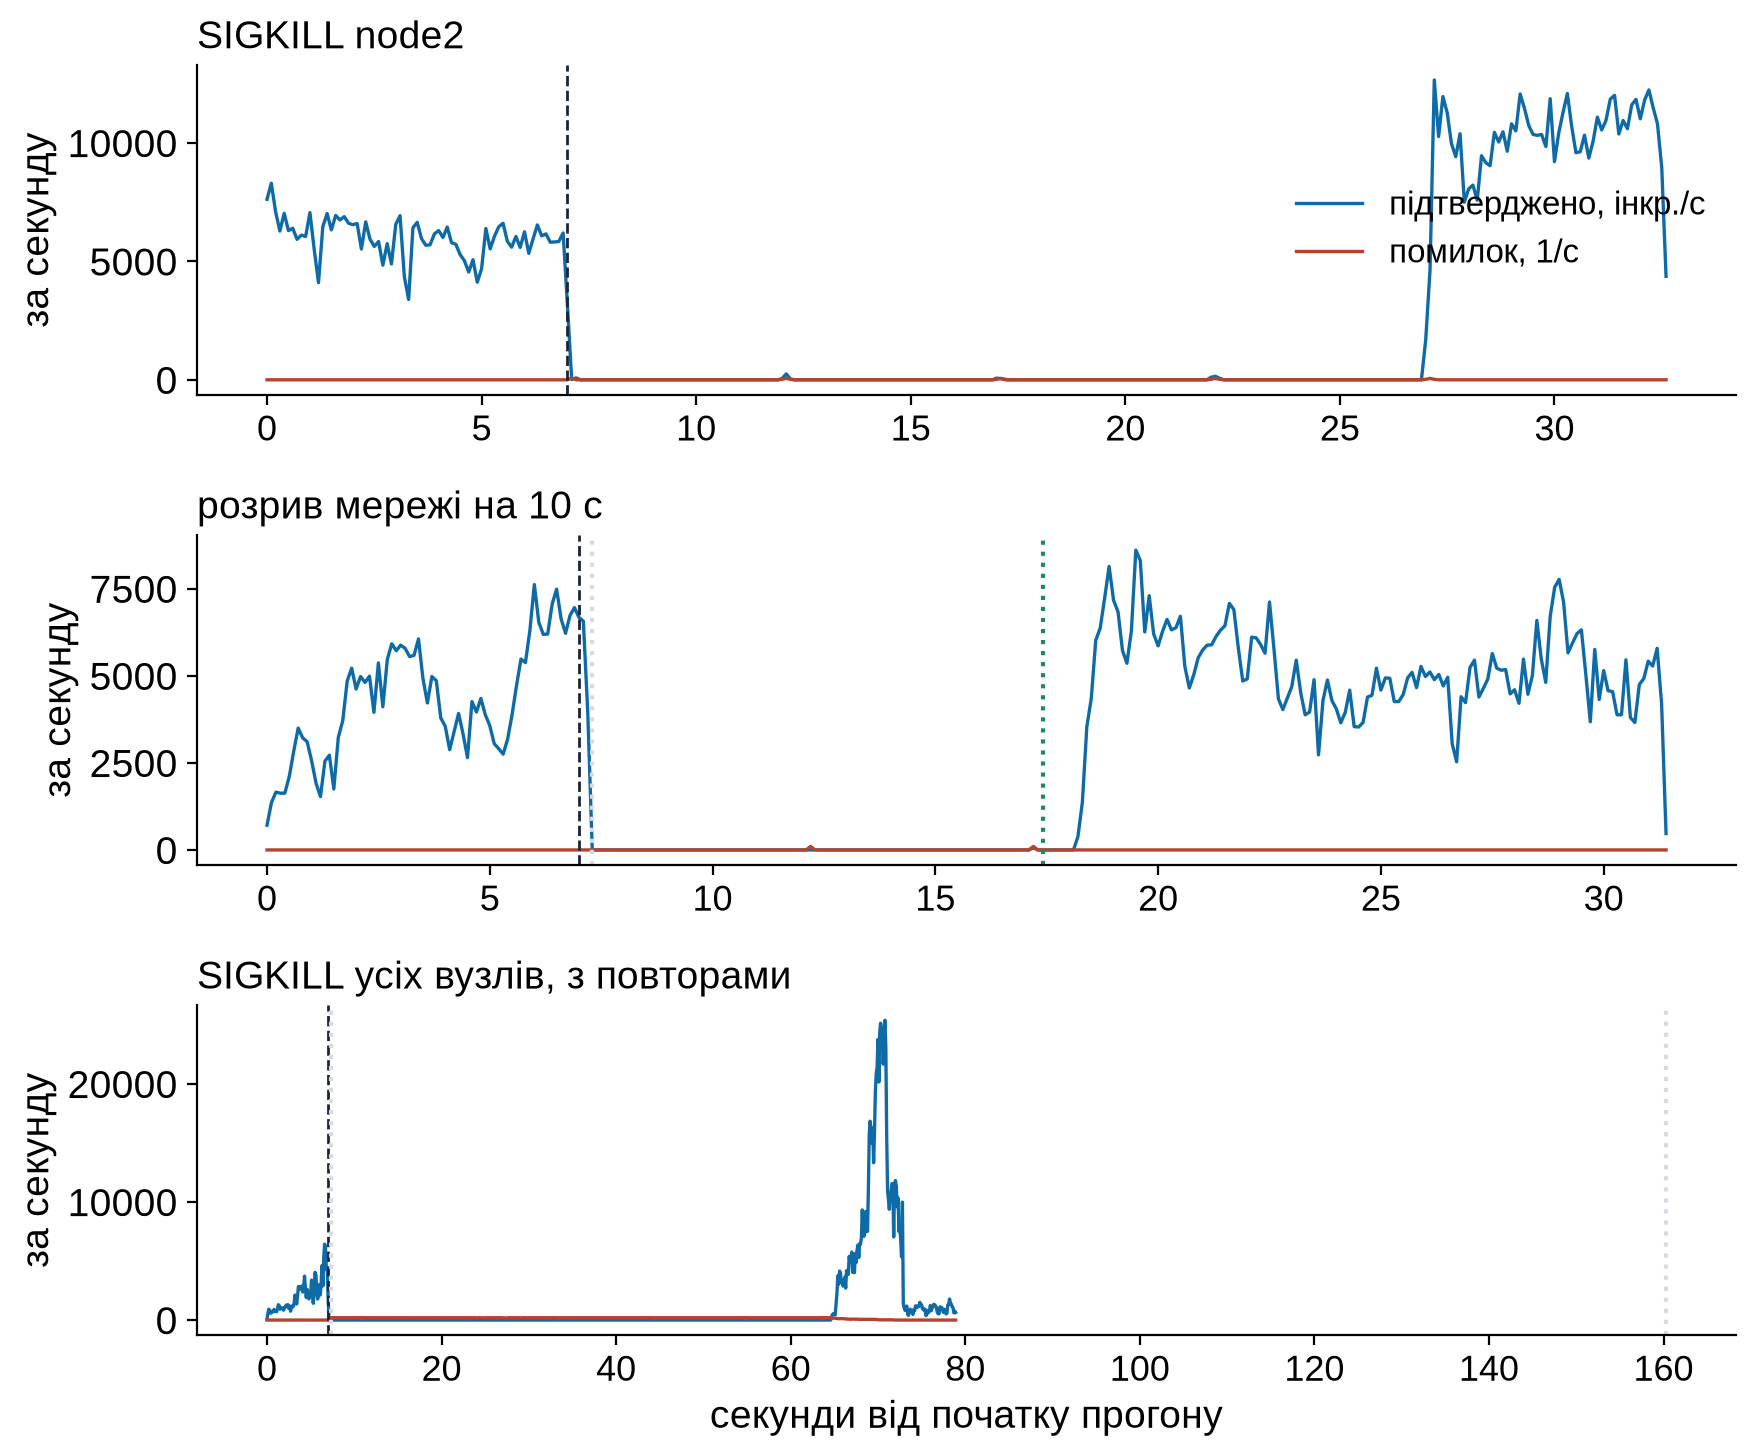

збережено: Labs/05-cassandra/assets/failure-timelines.png


In [17]:
def timeline(name: str):
    path = DATA / "task5x-timeline" / f"{name}.csv"
    marks = {}
    rows = []
    for line in path.read_text().splitlines()[1:]:
        if line.startswith("# "):
            what, at = line[2:].split(",")
            marks[what] = float(at)
        else:
            rows.append([float(x) for x in line.split(",")])
    return pd.DataFrame(rows, columns=["t", "ack", "failed"]), marks


fig, axes = plt.subplots(3, 1, figsize=(9, 7.5), sharex=False)
for ax, (name, title) in zip(axes, [("kill-one-1", "SIGKILL node2"), ("split-one-1", "розрив мережі на 10 с"),
                                    ("killall-one-retry-1", "SIGKILL усіх вузлів, з повторами")]):
    tl, marks = timeline(name)
    ax.plot(tl["t"], tl["ack"] * 10, color="#0E6BA8", lw=1.2, label="підтверджено, інкр./с")
    ax.plot(tl["t"], tl["failed"] * 10, color="#B5432F", lw=1.2, label="помилок, 1/с")
    at = fail.loc[(fail["label"] == name[:-2]) & (fail["repeat"] == 1), "disrupted_at_seconds"].iloc[0]
    ax.axvline(at, color=INK, ls="--", lw=1)
    for what, x in marks.items():
        ax.axvline(x, color=GRID if what != "heal" else "#1B8A5E", ls=":", lw=1.5)
    ax.set_title(title, loc="left")
    ax.set_ylabel("за секунду")
axes[0].legend(frameon=False, loc="center right")
axes[-1].set_xlabel("секунди від початку прогону")
fig.tight_layout()
save(fig, "failure-timelines.png")

## 8. Додаткове дослідження: commit log і збереженість

`scripts/task5x-durability.sh`: кластер перезапускається з
`commitlog_sync: periodic` (за замовчуванням), `batch` (fsync перед кожною
відповіддю) і `group` з вікном 10 мс; у кожному режимі тричі 10 × 10 000
інкрементів з ONE і QUORUM, а потім тричі SIGKILL усіх вузлів посеред
прогону з QUORUM. `waiting_on_commit` = приріст метрики JMX
`CommitLog.WaitingOnCommit` на всіх вузлах (записи, що чекали синхронізації).

In [18]:
dur = pd.read_csv(DATA / "task5x-durability.csv")
dur["disruption"] = dur["disruption"].fillna("")
plain = dur[dur["disruption"] == ""]
crash = dur[dur["disruption"] == "kill-all"]
g = plain.groupby(["label", "consistency"])
durability = pd.DataFrame({
    "інкр./с (медіана)": g["ops_per_sec"].median(),
    "p50, мс": g["p50_ms"].median(),
    "p99, мс": g["p99_ms"].median(),
    "очікувань синхронізації": g["waiting_on_commit"].median(),
    "фінальні значення": g["final_value"].agg(list),
}).reindex(["periodic", "batch", "group:10"], level=0)
display(durability)
lost = crash.assign(втрачено=(-crash["applied_unacknowledged"]).clip(lower=0)).groupby("label")["втрачено"].agg(list)
display(lost.reindex(["periodic", "batch", "group:10"]).to_frame("втрачено підтверджених при SIGKILL усіх вузлів"))
assert (crash.loc[crash["label"] != "periodic", "applied_unacknowledged"] >= 0).all()
assert (crash.loc[crash["label"] == "periodic", "applied_unacknowledged"] < 0).all()

інкр./с (медіана)  p50, мс  p99, мс  очікувань синхронізації         фінальні значення
label    consistency                                                                                        
periodic ONE                     3775.4    1.850   16.133                      0.0  [100000, 100000, 100000]
         QUORUM                  3284.0    2.043   13.321                      0.0  [100000, 100000, 100000]
batch    ONE                      323.3   25.628  102.421                 300275.0  [100000, 100000, 100000]
         QUORUM                   409.0   22.127   66.237                 300271.0  [100000, 100000, 100000]
group:10 ONE                      245.5   34.727  114.946                 300411.0  [100000, 100000, 100000]
         QUORUM                   257.0   34.116   91.012                 300298.0  [100000, 100000, 100000]

,втрачено підтверджених при SIGKILL усіх вузлів
label,
periodic,"[68, 335, 116]"
batch,"[0, 0, 0]"
group:10,"[0, 0, 0]"


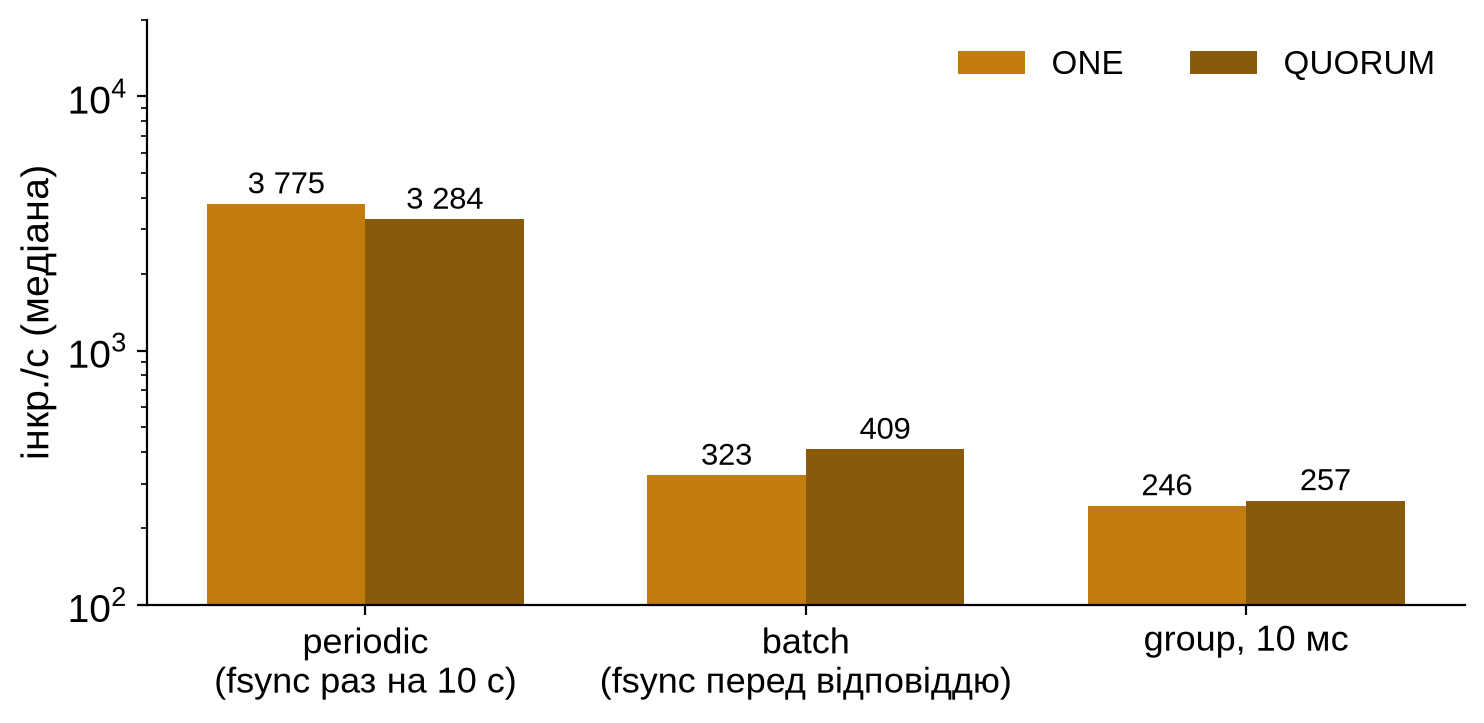

збережено: Labs/05-cassandra/assets/commitlog-modes.png


In [19]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
modes = ["periodic", "batch", "group:10"]
for i, level in enumerate(["ONE", "QUORUM"]):
    vals = [durability.loc[(m, level), "інкр./с (медіана)"] for m in modes]
    ax.bar([x + (i - 0.5) * 0.36 for x in range(3)], vals, 0.36, color=LEVEL_COLOR[level], label=level)
    for x, v in enumerate(vals):
        ax.text(x + (i - 0.5) * 0.36, v * 1.1, uk(v), ha="center", fontsize=11)
ax.set_yscale("log")
ax.set_xticks(range(3), ["periodic\n(fsync раз на 10 с)", "batch\n(fsync перед відповіддю)", "group, 10 мс"])
ax.set_ylabel("інкр./с (медіана)")
ax.set_ylim(100, 20000)
ax.legend(frameon=False, ncol=2, loc="upper right")
save(fig, "commitlog-modes.png")

## 9. Додаткове дослідження: власний клієнт CQL

`scripts/task5x-driver.sh`: 10 × 10 000 інкрементів з ONE і QUORUM через
apple/swift-cassandra-client (DataStax C++ driver), через наш `CQLClient`
(протокол v4 на SwiftNIO, token-aware) і через наш клієнт з розсиланням
по колу (`--no-token-aware`), по три повтори впереміж.

In [20]:
drv = pd.read_csv(DATA / "task5x-driver.csv")
g = drv.groupby(["label", "consistency"])
drivers = pd.DataFrame({
    "інкр./с (медіана)": g["ops_per_sec"].median(),
    "мін.": g["ops_per_sec"].min(),
    "макс.": g["ops_per_sec"].max(),
    "p50, мс": g["p50_ms"].median(),
    "p99, мс": g["p99_ms"].median(),
    "фінальні значення": g["final_value"].agg(list),
}).reindex(["datastax", "own", "own-round-robin"], level=0)
display(drivers)
assert (drv["final_value"] == EXPECTED).all() and (drv["errors"] == 0).all()
for level in ("ONE", "QUORUM"):
    own_, ds = drivers.loc[("own", level), "інкр./с (медіана)"], drivers.loc[("datastax", level), "інкр./с (медіана)"]
    rr = drivers.loc[("own-round-robin", level), "інкр./с (медіана)"]
    print(f"{level}: own / datastax {own_ / ds:.2f}, token-aware / round-robin {own_ / rr:.2f}")

інкр./с (медіана)    мін.   макс.  p50, мс  p99, мс         фінальні значення
label           consistency                                                                               
datastax        ONE                     5230.0  3173.1  5440.5    1.856    5.581  [100000, 100000, 100000]
                QUORUM                  4086.3  3849.5  4127.9    2.384    5.060  [100000, 100000, 100000]
own             ONE                     6234.5  5923.1  6793.1    1.599    4.391  [100000, 100000, 100000]
                QUORUM                  4641.2  4542.1  4795.3    2.113    4.643  [100000, 100000, 100000]
own-round-robin ONE                     5892.4  5057.1  6058.1    1.681    4.614  [100000, 100000, 100000]
                QUORUM                  4196.3  3941.5  4335.1    2.306    4.903  [100000, 100000, 100000]

ONE: own / datastax 1.19, token-aware / round-robin 1.06
QUORUM: own / datastax 1.14, token-aware / round-robin 1.11


In [21]:
excerpt("Sources/CQLClient/Cluster/Murmur3Partitioner.swift", "static func token", lines=12)

Sources/CQLClient/Cluster/Murmur3Partitioner.swift, рядки 11...22
  11 |     public static func token(of key: some Collection<UInt8>) -> Int64 {
  12 |         let h1 = hash3_x64_128(Array(key)).0
  13 |         // Long.MIN_VALUE is reserved as the minimum token of the ring.
  14 |         return h1 == .min ? .max : h1
  15 |     }
  16 | 
  17 |     public static func token(of key: ByteBuffer) -> Int64 {
  18 |         token(of: key.readableBytesView)
  19 |     }
  20 | 
  21 |     /// The routing key of a partition key: the single component's bytes, or
  22 |     /// for a composite key each component as a short length, the bytes and


## 10. Додаткове дослідження: застарілі читання і три способи інкременту

`scripts/task5x-anomalies.sh`, частина `reads`: лічильник з ONE або QUORUM і
читач з ONE або QUORUM поруч (усі чотири пари, по три повтори). Читання
застаріле, якщо повернуло менше, ніж уже було підтверджено інкрементів до
його надсилання. Частина `methods`: колонка `bigint` з read-modify-write
(ONE, QUORUM) і з легкою транзакцією (`IF value = ?`, читання SERIAL) поруч
з колонкою `counter`, 10 × 1 000 інкрементів.

In [22]:
an = pd.read_csv(DATA / "task5x-anomalies.csv")
reads = an[an["label"].str.startswith("w-")]
g = reads.groupby("label")
stale = pd.DataFrame({
    "читань (медіана)": g["reader_reads"].median(),
    "застарілих": g["reader_stale"].agg(list),
    "назад": g["reader_backwards"].agg(list),
    "найбільше відставання": g["reader_largest_shortfall"].agg(list),
}).loc[["w-one-r-one", "w-quorum-r-one", "w-one-r-quorum", "w-quorum-r-quorum"]]
display(stale)
assert stale.loc["w-quorum-r-quorum", "застарілих"] == [0, 0, 0]
assert min(stale.loc["w-one-r-one", "застарілих"]) > 0

,читань (медіана),застарілих,назад,найбільше відставання
label,,,,
w-one-r-one,5014.0,"[194.0, 28.0, 244.0]","[3.0, 0.0, 5.0]","[8.0, 4.0, 10.0]"
w-quorum-r-one,8798.0,"[1.0, 7.0, 7.0]","[0.0, 0.0, 91.0]","[1.0, 3.0, 3.0]"
w-one-r-quorum,2258.0,"[0.0, 0.0, 0.0]","[0.0, 0.0, 0.0]","[0.0, 0.0, 0.0]"
w-quorum-r-quorum,3959.0,"[0.0, 0.0, 0.0]","[0.0, 0.0, 0.0]","[0.0, 0.0, 0.0]"


In [23]:
methods = an[~an["label"].str.startswith("w-")]
g = methods.groupby("label")
incr = pd.DataFrame({
    "інкр./с (медіана)": g["ops_per_sec"].median(),
    "фінальні значення": g["final_value"].agg(list),
    "підтверджено": g["acknowledged"].agg(list),
    "помилок": g["errors"].agg(list),
    "конфліктів умови": g["conflicts"].agg(list),
    "p50, мс": g["p50_ms"].median(),
}).loc[["rmw-one", "rmw-quorum", "lwt-quorum", "counter-quorum"]]
display(incr)
rmw = methods[methods["label"].str.startswith("rmw")]
print(f"read-modify-write втратив {1 - rmw['final_value'].max() / 10_000:.0%}...{1 - rmw['final_value'].min() / 10_000:.0%} інкрементів")
lwt = methods[methods["label"] == "lwt-quorum"]
print("LWT: застосовано без підтвердження", lwt["applied_unacknowledged"].tolist(),
      "; втрачено підтверджених", int((lwt["applied_unacknowledged"] < 0).sum()))
assert (lwt["applied_unacknowledged"] >= 0).all() and (rmw["acknowledged"] == 10_000).all()

,інкр./с (медіана),фінальні значення,підтверджено,помилок,конфліктів умови,"p50, мс"
label,,,,,,
rmw-one,3194.5,"[1380, 1365, 1264]","[10000, 10000, 10000]","[0, 0, 0]","[0, 0, 0]",2.323
rmw-quorum,2187.7,"[1519, 1581, 1538]","[10000, 10000, 10000]","[0, 0, 0]","[0, 0, 0]",4.229
lwt-quorum,107.0,"[8727, 9140, 8886]","[8362, 8812, 8529]","[1638, 1188, 1471]","[3132, 2682, 3149]",5.081
counter-quorum,2043.3,"[10000, 10000, 10000]","[10000, 10000, 10000]","[0, 0, 0]","[0, 0, 0]",3.655


read-modify-write втратив 84%...87% інкрементів
LWT: застосовано без підтвердження [365, 328, 357] ; втрачено підтверджених 0


## 11. Жива перевірка

Якщо кластер запущено (`scripts/cassandra.sh start`), `cassandra-bench`
проганяє 10 × 300 інкрементів з ONE і з QUORUM. Числа звіту беруться не
звідси, а з CSV.

In [24]:
def cluster_running() -> bool:
    import socket
    try:
        with socket.create_connection(("127.0.0.11", 21440), timeout=1):
            return True
    except OSError:
        return False


bench_bin = ROOT / ".build" / "release" / "cassandra-bench"
if not RUN_LIVE:
    print("RUN_LIVE = False: пропускаю")
elif not bench_bin.is_file() or not cluster_running():
    print("кластер не запущено або cassandra-bench не зібрано: пропускаю "
          "(scripts/cassandra.sh start; swift build -c release --product cassandra-bench)")
else:
    live = []
    for level in ("one", "quorum"):
        out = subprocess.run([str(bench_bin), "--header", "--consistency", level, "--increments", "300"],
                             capture_output=True, text=True, timeout=600, check=True).stdout
        header, row = out.strip().splitlines()[-2:]
        live.append(dict(zip(header.split(","), row.split(","))))
    live = pd.DataFrame(live)[["consistency", "seconds", "ops_per_sec", "final_value", "expected", "errors", "p50_ms"]]
    display(live)
    assert (live["final_value"] == live["expected"]).all()

,consistency,seconds,ops_per_sec,final_value,expected,errors,p50_ms
0,ONE,0.3851,7790.3,3000,3000,0,1.363
1,QUORUM,0.5899,5085.7,3000,3000,0,2.012


## 12. Висновки

Числа нижче обчислено вище в цьому ноутбуці.

In [25]:
one, quorum = part3.loc["ONE"], part3.loc["QUORUM"]
print(f"Частина 2: Owns разом {', '.join(f'{v:.0f} %' for v in dist['сума owns, %'])} для RF 1, 2, 3;")
print("  рівень k доступний, коли живі щонайменше k реплік рядка;")
print(f"  конфлікти розв'язано за найбільшою міткою часу: {final.set_index('id')['значення'].to_dict()}")
print(f"Частина 3: ONE {uk(one['медіана, с'], 2)} с, QUORUM {uk(quorum['медіана, с'], 2)} с; "
      f"фінальні значення ONE {one['фінальні значення']}, QUORUM {quorum['фінальні значення']}")
for store, r in compare.iterrows():
    print(f"  {store}: {uk(r['запитів/с (медіана)'], 1)} запитів/с")
print("Відмови: kill і split без втрат підтверджених; killall (periodic) втратив", sorted((-ka["applied_unacknowledged"]).clip(lower=0).tolist()))
print("Commit log: periodic / batch за QUORUM", round(durability.loc[("periodic", "QUORUM"), "інкр./с (медіана)"] / durability.loc[("batch", "QUORUM"), "інкр./с (медіана)"], 1), "раза; batch і group без втрат")
print("Власний клієнт / DataStax:", round(drivers.loc[("own", "ONE"), "інкр./с (медіана)"] / drivers.loc[("datastax", "ONE"), "інкр./с (медіана)"], 2), "(ONE)")

Частина 2: Owns разом 100 %, 200 %, 300 % для RF 1, 2, 3;
  рівень k доступний, коли живі щонайменше k реплік рядка;
  конфлікти розв'язано за найбільшою міткою часу: {100: 'з node3', 101: 'з node1, раніше'}
Частина 3: ONE 22,42 с, QUORUM 28,43 с; фінальні значення ONE [100000, 100000, 100000], QUORUM [100000, 100000, 100000]
  In-memory: 31 256,0 запитів/с
  Hazelcast (CP): 11 259,7 запитів/с
  Cassandra ONE: 3 654,6 запитів/с
  Cassandra QUORUM: 3 164,4 запитів/с
  MongoDB (majority): 748,6 запитів/с
  PostgreSQL: 330,6 запитів/с
  Disk (fsync): 122,2 запитів/с
Відмови: kill і split без втрат підтверджених; killall (periodic) втратив [0, 1, 1, 27, 42, 73, 117, 127, 185]
Commit log: periodic / batch за QUORUM 8.0 раза; batch і group без втрат
Власний клієнт / DataStax: 1.19 (ONE)
